Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dataset loaded from: /content/drive/MyDrive/Housing.csv
Dataset shape: (545, 13)

Training samples: 436
Testing samples: 109
Internal training samples: 348
Validation samples: 88

Neural Network Architecture:
Sequential(
  (0): Linear(in_features=13, out_features=32, bias=True)
  (1): ReLU()
  (2): Linear(in_features=32, out_features=16, bias=True)
  (3): ReLU()
  (4): Linear(in_features=16, out_features=1, bias=True)
)
Epoch   1 | Training Loss: 0.997628 | Validation Loss: 1.013746
Epoch  10 | Training Loss: 0.922174 | Validation Loss: 0.946336
Epoch  20 | Training Loss: 0.828352 | Validation Loss: 0.854099
Epoch  30 | Training Loss: 0.715986 | Validation Loss: 0.742485
Epoch  40 | Training Loss: 0.597559 | Validation Loss: 0.622429
Epoch  50 | Training Loss: 0.493931 | Validation Loss: 0.523420
Epoch  60 | Training Loss: 0.417358 | Validation Loss: 0.466532

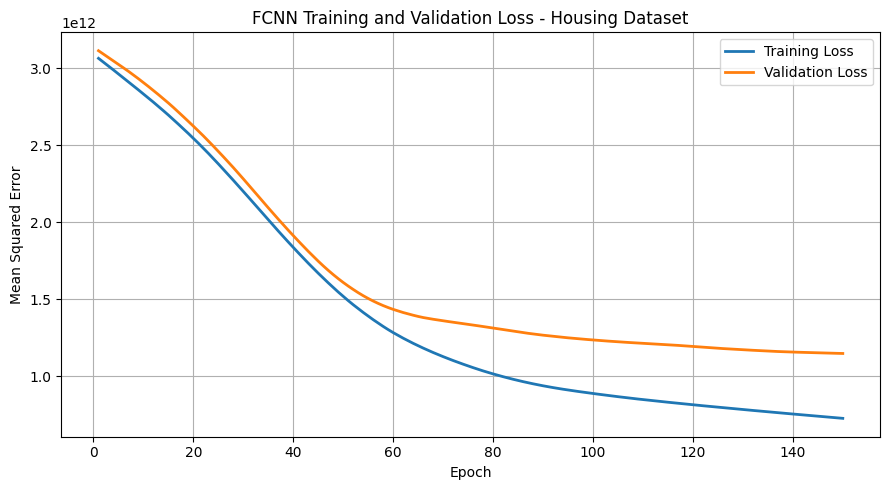


========== PROBLEM 1.a ==========

Neural Network Architecture:
Sequential(
  (0): Linear(in_features=13, out_features=32, bias=True)
  (1): ReLU()
  (2): Linear(in_features=32, out_features=16, bias=True)
  (3): ReLU()
  (4): Linear(in_features=16, out_features=1, bias=True)
)

Hyperparameters:
Hidden layers: 2
Neurons: 32, 16
Activation function: ReLU
Output activation: Linear
Loss function: MSE
Optimizer: Adam
Learning rate: 0.001
Epochs: 150
Training method: Full-batch gradient updates
Early stopping: Not used

FCNN Test Performance:
MSE:  1,726,880,022,528.0000
RMSE: 1,314,108.0711
R2:   0.6584

========== PROBLEM 1.b ==========

Test Performance Comparison:
            Model                    MSE           RMSE     R2
             FCNN 1,726,880,022,528.0000 1,314,108.0711 0.6584
Linear Regression 1,754,318,687,330.6667 1,324,506.9601 0.6529
              SVR 2,150,666,336,496.0203 1,466,515.0311 0.5745

Best Performing Model: FCNN
The FCNN outperforms Linear Regression and SVR

In [6]:

# ============================================================
# HOMEWORK 6 - PROBLEM 1: HOUSING PRICE PREDICTION
# Problem 1.a: Fully Connected Neural Network
# Problem 1.b: Comparison with Linear Regression and SVR
#
# Following Dr. Hamed Tabkhi's Introduction to ML
# lecture examples and GitHub repository:
# https://github.com/HamedTabkhi/Intro-to-ML
# ============================================================

# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================

import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim

from google.colab import drive
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.metrics import mean_squared_error, r2_score


# ============================================================
# 2. MOUNT GOOGLE DRIVE AND LOAD HOUSING DATASET
# ============================================================

drive.mount('/content/drive')

file_path = None

for root, dirs, files in os.walk('/content/drive/MyDrive'):
    for file in files:
        if file.lower() in [
            'housing.csv',
            'housing(1).csv',
            'housing(2).csv'
        ]:
            file_path = os.path.join(root, file)
            break

    if file_path is not None:
        break

if file_path is None:
    raise FileNotFoundError(
        "Housing dataset not found in Google Drive."
    )

df = pd.read_csv(file_path)

print("Dataset loaded from:", file_path)
print("Dataset shape:", df.shape)


# ============================================================
# 3. SET RANDOM SEED
# ============================================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)


# ============================================================
# 4. SEPARATE FEATURES AND TARGET
# ============================================================

X = df.drop(columns=['price']).copy()
y = df['price'].values

numerical_features = [
    'area',
    'bedrooms',
    'bathrooms',
    'stories',
    'parking'
]

binary_features = [
    'mainroad',
    'guestroom',
    'basement',
    'hotwaterheating',
    'airconditioning',
    'prefarea'
]

# Convert yes/no features to numerical values.

for column in binary_features:
    X[column] = X[column].map({
        'yes': 1,
        'no': 0
    })


# ============================================================
# 5. TRAINING AND TESTING SPLIT (80% / 20%)
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=SEED
)

# Split training data again for neural network validation.
# The test set is reserved for final evaluation.

X_fit, X_val, y_fit, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=SEED
)

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Internal training samples:", len(X_fit))
print("Validation samples:", len(X_val))


# ============================================================
# 6. INPUT STANDARDIZATION
# ============================================================

def make_preprocessor():

    return ColumnTransformer([
        (
            'numerical',
            StandardScaler(),
            numerical_features
        ),
        (
            'binary',
            'passthrough',
            binary_features
        ),
        (
            'furnishing',
            OneHotEncoder(
                drop='first',
                handle_unknown='ignore',
                sparse_output=False
            ),
            ['furnishingstatus']
        )
    ])


# Fit preprocessing only on internal training data.

preprocessor_val = make_preprocessor()

X_fit_scaled = preprocessor_val.fit_transform(X_fit)
X_val_scaled = preprocessor_val.transform(X_val)

# Standardize target for stable neural network training.

y_scaler_val = StandardScaler()

y_fit_scaled = y_scaler_val.fit_transform(
    y_fit.reshape(-1, 1)
)

y_val_scaled = y_scaler_val.transform(
    y_val.reshape(-1, 1)
)


# ============================================================
# PROBLEM 1.a: FULLY CONNECTED NEURAL NETWORK
# ============================================================

# ============================================================
# 7. CONVERT NUMPY ARRAYS TO PYTORCH TENSORS
# ============================================================

X_fit_tensor = torch.tensor(
    X_fit_scaled,
    dtype=torch.float32
)

y_fit_tensor = torch.tensor(
    y_fit_scaled,
    dtype=torch.float32
)

X_val_tensor = torch.tensor(
    X_val_scaled,
    dtype=torch.float32
)

y_val_tensor = torch.tensor(
    y_val_scaled,
    dtype=torch.float32
)


# ============================================================
# 8. DEFINE FULLY CONNECTED NEURAL NETWORK
# ============================================================

# Input layer: all encoded input features
# Hidden layer 1: 32 neurons, ReLU
# Hidden layer 2: 16 neurons, ReLU
# Output layer: 1 neuron, linear activation

def create_model(input_size):

    model = nn.Sequential(
        nn.Linear(input_size, 32),
        nn.ReLU(),

        nn.Linear(32, 16),
        nn.ReLU(),

        nn.Linear(16, 1)
    )

    return model


input_size = X_fit_tensor.shape[1]

model = create_model(input_size)

print("\nNeural Network Architecture:")
print(model)


# ============================================================
# 9. LOSS FUNCTION AND OPTIMIZER
# ============================================================

learning_rate = 0.001
num_epochs = 150

loss_fn = nn.MSELoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=learning_rate
)


# ============================================================
# 10. TRAINING AND VALIDATION LOOP
# ============================================================

# Fixed-epoch training, following Dr. Tabkhi's lecture style.
# No early stopping.
# Only training loss is used for backpropagation.

train_losses = []
val_losses = []

for epoch in range(1, num_epochs + 1):

    # Training mode
    model.train()

    # Forward pass
    train_predictions = model(X_fit_tensor)

    # Calculate training loss
    train_loss = loss_fn(
        train_predictions,
        y_fit_tensor
    )

    # Backpropagation and parameter update
    optimizer.zero_grad()

    train_loss.backward()

    optimizer.step()

    # Validation (no gradient calculation)
    model.eval()

    with torch.no_grad():

        # Calculate updated training loss
        train_predictions = model(X_fit_tensor)

        train_loss = loss_fn(
            train_predictions,
            y_fit_tensor
        )

        # Calculate validation loss
        val_predictions = model(X_val_tensor)

        val_loss = loss_fn(
            val_predictions,
            y_val_tensor
        )

    # Store training and validation losses
    train_losses.append(train_loss.item())
    val_losses.append(val_loss.item())

    # Print progress
    if epoch == 1 or epoch % 10 == 0:

        print(
            f"Epoch {epoch:3d} | "
            f"Training Loss: {train_loss.item():.6f} | "
            f"Validation Loss: {val_loss.item():.6f}"
        )


# ============================================================
# 11. PLOT TRAINING AND VALIDATION LOSSES
# ============================================================

# Convert standardized-target MSE to original price-squared MSE.

price_scale_squared = y_scaler_val.scale_[0] ** 2

train_losses_original = (
    np.array(train_losses) * price_scale_squared
)

val_losses_original = (
    np.array(val_losses) * price_scale_squared
)

plt.figure(figsize=(9, 5))

plt.plot(
    range(1, num_epochs + 1),
    train_losses_original,
    label='Training Loss',
    linewidth=2
)

plt.plot(
    range(1, num_epochs + 1),
    val_losses_original,
    label='Validation Loss',
    linewidth=2
)

plt.xlabel('Epoch')
plt.ylabel('Mean Squared Error')
plt.title('FCNN Training and Validation Loss - Housing Dataset')
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.show()


# ============================================================
# 12. TRAIN FINAL FCNN ON THE FULL 80% TRAINING SET
# ============================================================

# Fit preprocessing using all training data only.

preprocessor = make_preprocessor()

X_train_scaled = preprocessor.fit_transform(X_train)
X_test_scaled = preprocessor.transform(X_test)

# Standardize training target.

y_scaler = StandardScaler()

y_train_scaled = y_scaler.fit_transform(
    y_train.reshape(-1, 1)
)

# Convert arrays to tensors.

X_train_tensor = torch.tensor(
    X_train_scaled,
    dtype=torch.float32
)

y_train_tensor = torch.tensor(
    y_train_scaled,
    dtype=torch.float32
)

X_test_tensor = torch.tensor(
    X_test_scaled,
    dtype=torch.float32
)

# Initialize a fresh neural network.

torch.manual_seed(SEED)

final_model = create_model(
    X_train_tensor.shape[1]
)

final_optimizer = optim.Adam(
    final_model.parameters(),
    lr=learning_rate
)

# Train for the same fixed number of epochs.

for epoch in range(1, num_epochs + 1):

    final_model.train()

    # Forward pass
    predictions = final_model(X_train_tensor)

    # Calculate loss
    loss = loss_fn(
        predictions,
        y_train_tensor
    )

    # Backpropagation
    final_optimizer.zero_grad()

    loss.backward()

    # Update weights
    final_optimizer.step()


# ============================================================
# 13. FCNN TEST PREDICTIONS
# ============================================================

final_model.eval()

with torch.no_grad():

    y_pred_scaled = final_model(
        X_test_tensor
    ).numpy()

# Convert predictions back to actual housing prices.

y_pred_fcnn = y_scaler.inverse_transform(
    y_pred_scaled
).ravel()


# ============================================================
# 14. FCNN EVALUATION
# ============================================================

fcnn_mse = mean_squared_error(
    y_test,
    y_pred_fcnn
)

fcnn_rmse = np.sqrt(fcnn_mse)

fcnn_r2 = r2_score(
    y_test,
    y_pred_fcnn
)

print("\n========== PROBLEM 1.a ==========")

print("\nNeural Network Architecture:")
print(final_model)

print("\nHyperparameters:")
print("Hidden layers: 2")
print("Neurons: 32, 16")
print("Activation function: ReLU")
print("Output activation: Linear")
print("Loss function: MSE")
print("Optimizer: Adam")
print("Learning rate:", learning_rate)
print("Epochs:", num_epochs)
print("Training method: Full-batch gradient updates")
print("Early stopping: Not used")

print("\nFCNN Test Performance:")
print(f"MSE:  {fcnn_mse:,.4f}")
print(f"RMSE: {fcnn_rmse:,.4f}")
print(f"R2:   {fcnn_r2:.4f}")


# ============================================================
# PROBLEM 1.b: TRADITIONAL MACHINE LEARNING COMPARISON
# ============================================================

# ============================================================
# 15. LINEAR REGRESSION
# ============================================================

linear_model = LinearRegression()

linear_model.fit(
    X_train_scaled,
    y_train
)

y_pred_linear = linear_model.predict(
    X_test_scaled
)

linear_mse = mean_squared_error(
    y_test,
    y_pred_linear
)

linear_rmse = np.sqrt(linear_mse)

linear_r2 = r2_score(
    y_test,
    y_pred_linear
)


# ============================================================
# 16. SUPPORT VECTOR REGRESSION (SVR)
# ============================================================

# RBF kernel, following the SVR example from the course.
# Standardize target values for SVR optimization.

svr_model = TransformedTargetRegressor(
    regressor=SVR(
        kernel='rbf',
        C=10,
        gamma='scale',
        epsilon=0.1
    ),
    transformer=StandardScaler()
)

svr_model.fit(
    X_train_scaled,
    y_train
)

y_pred_svr = svr_model.predict(
    X_test_scaled
)

svr_mse = mean_squared_error(
    y_test,
    y_pred_svr
)

svr_rmse = np.sqrt(svr_mse)

svr_r2 = r2_score(
    y_test,
    y_pred_svr
)


# ============================================================
# 17. COMPARISON TABLE
# ============================================================

results = pd.DataFrame({

    'Model': [
        'FCNN',
        'Linear Regression',
        'SVR'
    ],

    'MSE': [
        fcnn_mse,
        linear_mse,
        svr_mse
    ],

    'RMSE': [
        fcnn_rmse,
        linear_rmse,
        svr_rmse
    ],

    'R2': [
        fcnn_r2,
        linear_r2,
        svr_r2
    ]

})

print("\n========== PROBLEM 1.b ==========")

print("\nTest Performance Comparison:")

print(
    results.to_string(
        index=False,
        float_format=lambda x: f"{x:,.4f}"
    )
)


# ============================================================
# 18. IDENTIFY BEST MODEL
# ============================================================

best_model = results.loc[
    results['RMSE'].idxmin(),
    'Model'
]

print("\nBest Performing Model:", best_model)

if best_model == 'FCNN':

    print(
        "The FCNN outperforms Linear Regression and SVR "
        "on the test dataset."
    )

else:

    print(
        "The FCNN does not outperform both traditional "
        "regression methods on the test dataset."
    )
